# Del texto de Borges al próximo token

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---
| | |
|---|---|
| **Problema** | Un modelo generativo no recibe un texto: recibe ejemplos numéricos de qué token debería seguir. |
| **Producto** | Una cadena verificable desde un fragmento de Borges hasta pares de entrada y objetivo para un modelo causal. |
| **Recursos** | Computadora local y GPT-2 en español (`DeepESP/gpt2-spanish`, unos 250 MB, descargado antes de la clase según `ANTES_DE_LA_CLASE.md`). Es el mismo modelo del laboratorio y de la unidad 011. |

El laboratorio GPT-2 que sigue puede ajustar un modelo a un corpus. Antes necesitamos abrir la transformación que hace posible ese ajuste: convertir un texto en muchos ejemplos de predicción del próximo token.

**¿Cómo se transforma Tlön, Uqbar, Orbis Tertius en pares que un Transformer causal puede usar para aprender?**

> **Cómo se trabaja.** Explorás el recorrido con el texto completo y con una ventana pequeña que se puede leer. Al final de cada bloque hay un microlaboratorio con una comprobación.


In [1]:
from pathlib import Path

import numpy as np
import torch
import transformers
from transformers import AutoTokenizer, GPT2LMHeadModel
from transformers.utils import logging as registro

import visualizacion_texto as visual

MODELO = "DeepESP/gpt2-spanish"
RUTA_TEXTO = Path("tlon-uqbar-orbis-tertius.txt")

# Oculta los avisos de descarga; los errores se siguen mostrando.
registro.set_verbosity_error()
tokenizador = AutoTokenizer.from_pretrained(MODELO)
modelo = GPT2LMHeadModel.from_pretrained(MODELO)
modelo.eval()

version_de_transformers = transformers.__version__
version_de_torch = torch.__version__
tamano_del_vocabulario = len(tokenizador)
print(f"transformers {version_de_transformers}, torch {version_de_torch}")
print(f"Vocabulario del tokenizador: {tamano_del_vocabulario} tokens")

transformers 4.57.6, torch 2.14.1+cpu
Vocabulario del tokenizador: 50257 tokens


## 1. Un texto real, con una procedencia que importa

Trabajamos con una copia local de Tlön, Uqbar, Orbis Tertius, de Jorge Luis Borges. El archivo fue incorporado antes a la unidad como texto de estudio. Esta lectura no evalúa a Borges ni afirma que un modelo aprenda su estilo: muestra qué datos recibe un modelo generativo.


In [2]:
texto_completo = RUTA_TEXTO.read_text(encoding="utf-8")
fragmento = texto_completo[:400]

print(f"Caracteres en el archivo: {len(texto_completo):,}")
print()
print(fragmento)


Caracteres en el archivo: 32,516

Debo a la conjunción de un espejo y de una enciclopedia el descubrimiento de Uqbar. El espejo inquietaba el fondo de un corredor en una quinta de la calle Gaona, en Ramos Mejía; la enciclopedia falazmente se llama The Anglo-American Cyclopaedía (New York, 1917) y es una reimpresión literal, pero también morosa, de la Encyclopaedia Britannica de 1902. El hecho se produjo hará unos cinco años. Bioy 


> **Para mirar.** La computadora todavía ve caracteres. Ni las palabras ni sus límites son una unidad natural para el modelo: el siguiente paso decide cómo partir esta secuencia.

## 2. BPE evita un vocabulario cerrado

GPT-2 usa codificación por pares de bytes, o BPE. Usamos el tokenizador de GPT-2 en español, el mismo del laboratorio: su vocabulario se armó con texto en español. Un token puede coincidir con una palabra, con parte de una palabra, con puntuación o con espacios codificados. Por eso es importante mirar los tokens concretos y no asumir que una palabra siempre equivale a un token.


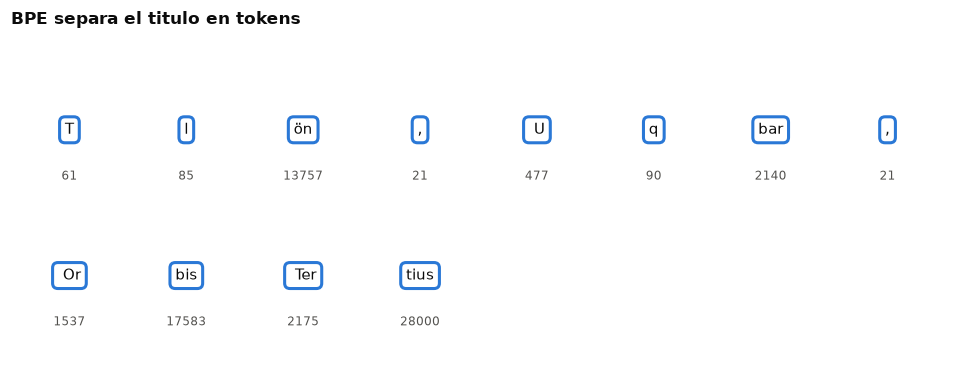

['T', 'l', 'ön', ',', ' U', 'q', 'bar', ',', ' Or', 'bis', ' Ter', 'tius']
Correcto.


In [3]:
texto_corto = "Tlön, Uqbar, Orbis Tertius"
ids_cortos = tokenizador.encode(texto_corto)
tokens_cortos = []

for identificador in ids_cortos:
    tokens_cortos.append(tokenizador.decode([identificador]))

notas = []
for identificador in ids_cortos:
    notas.append(str(identificador))

visual.dibujar_fichas(
    piezas=tokens_cortos,
    titulo="BPE separa el titulo en tokens",
    notas=notas,
)

texto_reconstruido = tokenizador.decode(ids_cortos)
print(tokens_cortos)
visual.comprobar(
    texto_reconstruido == texto_corto,
    "revisa que uses el mismo tokenizador para codificar y decodificar.",
)


> **Para mirar.** *Tlön* se parte en `T`, `l` y `ön`, y *Uqbar* en `U`, `q` y `bar`: los nombres que inventó Borges no están en el vocabulario, que se armó con secuencias frecuentes del español. Los identificadores no ordenan palabras por significado: son direcciones en el vocabulario del tokenizador. El texto puede reconstruirse porque el mismo tokenizador sabe deshacer esa codificación.

## 3. Una ventana convierte la lectura en una tarea de predicción

El modelo no recibe el libro entero como una sola entrada. Tomamos una ventana de tokens y la desplazamos un lugar. La entrada contiene lo que ya se conoce; el objetivo contiene exactamente el token que debería seguir en cada posición.


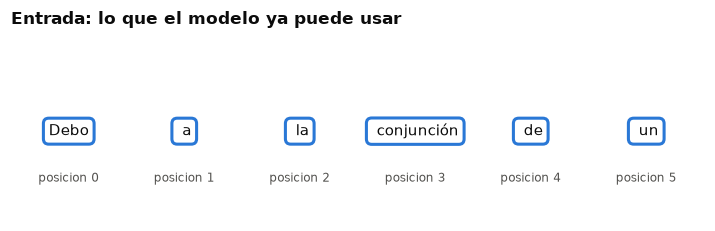

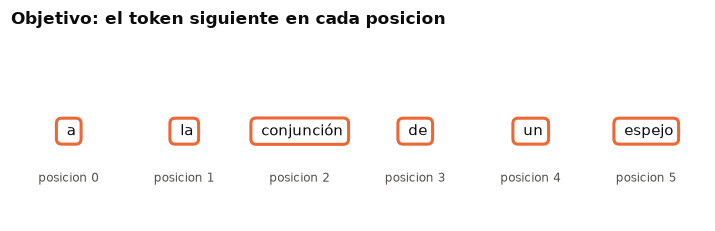

In [4]:
fragmento = texto_completo[:400]
ids_fragmento = tokenizador.encode(fragmento)
tokens_fragmento = []

for identificador in ids_fragmento:
    tokens_fragmento.append(tokenizador.decode([identificador]))

largo_ventana = 6
entrada_tokens = tokens_fragmento[:largo_ventana]
objetivo_tokens = tokens_fragmento[1:largo_ventana + 1]

colores_entrada = []
notas_posicion = []
for posicion in range(largo_ventana):
    colores_entrada.append(visual.AZUL)
    notas_posicion.append(f"posicion {posicion}")

visual.dibujar_fichas(
    piezas=entrada_tokens,
    titulo="Entrada: lo que el modelo ya puede usar",
    colores=colores_entrada,
    notas=notas_posicion,
)
colores_objetivo = []
for posicion in range(largo_ventana):
    colores_objetivo.append(visual.NARANJA)

visual.dibujar_fichas(
    piezas=objetivo_tokens,
    titulo="Objetivo: el token siguiente en cada posicion",
    colores=colores_objetivo,
    notas=notas_posicion,
)


> **Para mirar.** No hay seis predicciones independientes: el objetivo de la primera posición es el segundo token de la entrada, y así sucesivamente. Este desplazamiento de un lugar es la tarea causal que GPT-2 aprende.

### Microlaboratorio 1 — Desplazar la ventana

**Tarea.** Construí el objetivo que corresponde a una entrada de cuatro tokens.  
**Producto.** Una lista que empieza en el segundo token de entrada y suma el quinto token del fragmento.

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) | los cuatro tokens de entrada | el corte inicial de tokens_fragmento |
| (2) | los cuatro objetivos desplazados | el corte que comienza una posición después |

> **Ayuda 1.** Compará la posición inicial de entrada_tokens y objetivo_tokens.  
> **Ayuda 2.** Un corte de cuatro elementos que comienza en 1 termina antes de 5.


In [5]:
entrada_practica = []  # COMPLETAR (1)
objetivo_practica = []  # COMPLETAR (2)

visual.comprobar(
    entrada_practica == tokens_fragmento[:4]
    and objetivo_practica == tokens_fragmento[1:5],
    "revisa ambos cortes: deben tener cuatro tokens y estar "
    "desplazados un lugar.",
)


Todavia no. revisa ambos cortes: deben tener cuatro tokens y estar desplazados un lugar.


## 4. La posición no puede perderse

Attention relaciona todos los tokens disponibles, pero por sí sola no sabe cuál apareció primero. Por eso cada posición tiene un vector propio, que se suma al embedding del token. GPT-2 los guarda en una tabla: una fila por posición, hasta 1024, y 768 números por fila. Nadie los escribió: se aprendieron en el entrenamiento.

Mostramos un **recorte real**: las posiciones 0 a 5, con sus 8 primeras coordenadas.

Tabla de posiciones: (1024, 768)


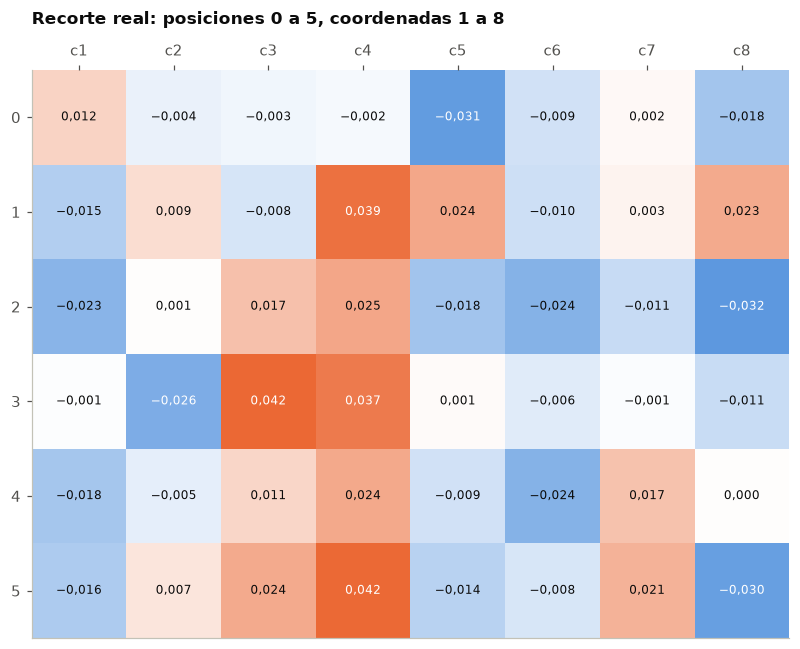

In [6]:
tabla_de_posiciones = modelo.transformer.wpe.weight.detach().numpy()
print(f"Tabla de posiciones: {tabla_de_posiciones.shape}")

recorte_de_posiciones = tabla_de_posiciones[0:6, 0:8]
posiciones = ["0", "1", "2", "3", "4", "5"]
coordenadas = []
for numero in range(8):
    coordenadas.append(f"c{numero + 1}")

visual.dibujar_mapa_con_signo(
    matriz=recorte_de_posiciones,
    filas=posiciones,
    columnas=coordenadas,
    titulo="Recorte real: posiciones 0 a 5, coordenadas 1 a 8",
)

> **Para mirar.** Cada posición es un vector distinto, de números chicos (no pasan de ±0,04 en este recorte), y ninguna columna se lee como «primero» o «tercero»: el orden está repartido en los 768 números. En la unidad 011 vimos que la atención causal bloquea el futuro; acá, qué lugar tiene cada token que queda disponible.

## 5. Del ejemplo al ciclo generativo

Durante el ajuste, el modelo compara sus predicciones con los objetivos desplazados y modifica sus pesos. Durante la generación, no tiene objetivos: toma un prefijo, calcula probabilidades para el próximo token, elige uno según una regla de muestreo y vuelve a empezar.

Le damos al modelo la primera oración de Borges, cortada justo antes de una palabra, y miramos qué propone. **Python nuevo:** `torch.no_grad()` avisa que no vamos a entrenar; `logits` trae un puntaje por token del vocabulario, y softmax los convierte en probabilidades.

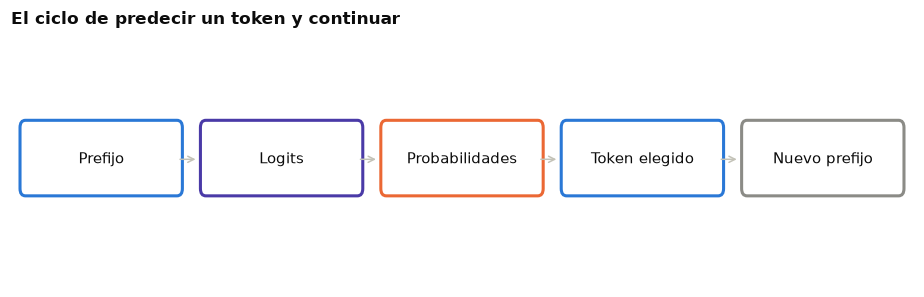

'enciclopedia', la palabra de Borges, queda en el puesto 733


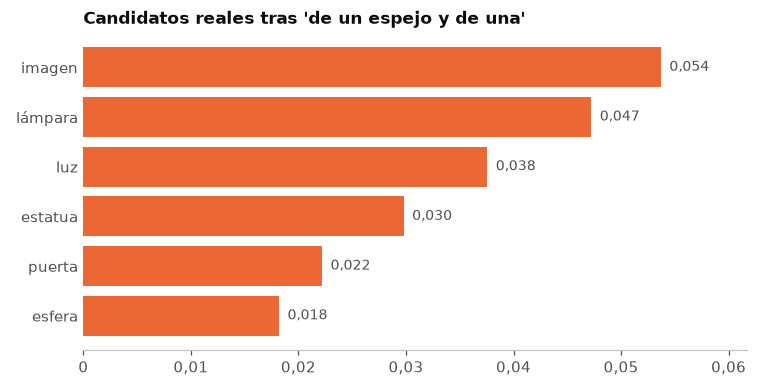

In [7]:
visual.dibujar_ciclo()

prefijo = "Debo a la conjunción de un espejo y de una"
ids_del_prefijo = tokenizador(prefijo, return_tensors="pt")["input_ids"]
with torch.no_grad():
    salida = modelo(ids_del_prefijo)

# El ultimo renglon de logits responde que viene despues del prefijo.
logits_del_prefijo = salida.logits[0].numpy()
ultimos_logits = logits_del_prefijo[-1]
exponenciales = np.exp(ultimos_logits - ultimos_logits.max())
probabilidades = exponenciales / exponenciales.sum()
orden = np.argsort(-probabilidades)

candidatos = []
valores = []
for numero in orden[0:6]:
    candidatos.append(tokenizador.decode([int(numero)]))
    valores.append(probabilidades[numero])

id_de_enciclopedia = tokenizador.encode(" enciclopedia")[0]
lugares = np.where(orden == id_de_enciclopedia)[0]
puesto_de_enciclopedia = int(lugares[0]) + 1
print(f"'enciclopedia', la palabra de Borges, queda en el puesto "
      f"{puesto_de_enciclopedia}")
visual.dibujar_barras(
    nombres=candidatos,
    valores=valores,
    titulo="Candidatos reales tras 'de un espejo y de una'",
    color=visual.NARANJA,
)

> **Para mirar.** El modelo propone objetos que pueden acompañar a un espejo (*imagen*, *lámpara*, *luz*), y ninguno pasa de 0,06: hay muchas continuaciones posibles. *Enciclopedia*, la que eligió Borges, queda en el puesto 733. En el laboratorio GPT-2 van a ver cómo cambia esta distribución al ajustar los pesos con otro corpus, y a distinguirlo de cambiar la regla de muestreo.

## Qué te llevás

- BPE convierte el texto en tokens e identificadores sin depender de un vocabulario de palabras completo.
- Una ventana y su objetivo desplazado construyen la tarea de predecir el próximo token.
- Los embeddings de token y de posición pasan a un Transformer causal como el que abrimos en 011.

**Sigue:** en el laboratorio GPT-2, el modelo base recibirá bloques de este tipo; van a decidir qué corpus usar, ajustar el modelo y evaluar qué evidencia queda del cambio.
